# 05 · Conversion Prediction & Campaign Targeting
**Question:** before dialling, can we rank customers by their likelihood to subscribe — so the call centre phones the best prospects first?

**Design choices**
* **No leakage:** `duration` (known only after the call) is excluded. A comparison model *with* duration is shown only to demonstrate the leakage effect.
* **Imbalanced target (11%)** → judged by ROC-AUC, PR-AUC, and lift/gains, not accuracy.
* 80/20 stratified train/test split; 5-fold CV on the training set for model selection; test set touched once for final numbers.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path("..")
FIG, TAB = ROOT / "outputs/figures", ROOT / "outputs/tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)

NAVY, TEAL, ORANGE, GREY = "#1F3A5F", "#2A9D8F", "#E76F51", "#9AA5B1"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "font.size": 10})
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 140)

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.inspection import permutation_importance
df = pd.read_csv(ROOT / "data/bank_marketing_clean.csv"); BASE = df.subscribed.mean()

## 1. Features and split

In [2]:
CAT = ["job", "marital", "education", "default", "housing", "loan", "contact", "month", "day_of_week", "poutcome"]
NUM = ["age", "campaign_capped", "previous", "prev_contacted", "emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"]
FEATURES = CAT + NUM
X, y = df[FEATURES], df.subscribed
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.2, stratify=y, random_state=42)
print(f"Train {Xtr.shape[0]:,}  |  Test {Xte.shape[0]:,}  |  positives: train {ytr.mean():.2%}, test {yte.mean():.2%}")

def make_pre(scale):
    return ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
                              ("num", StandardScaler() if scale else "passthrough", NUM)], sparse_threshold=0)
models = {
 "Logistic Regression": Pipeline([("pre", make_pre(True)), ("m", LogisticRegression(max_iter=3000, C=.5, class_weight="balanced"))]),
 "Random Forest": Pipeline([("pre", make_pre(False)), ("m", RandomForestClassifier(300, min_samples_leaf=20, class_weight="balanced_subsample", n_jobs=-1, random_state=42))]),
 "Gradient Boosting": Pipeline([("pre", make_pre(False)), ("m", HistGradientBoostingClassifier(learning_rate=.05, max_iter=250, max_leaf_nodes=15, l2_regularization=1.0, random_state=42))]),
}

Train 32,940  |  Test 8,236  |  positives: train 11.27%, test 11.27%


## 2. Model comparison

In [3]:
skf = StratifiedKFold(5, shuffle=True, random_state=42); rows = []; probs = {}
for name, pipe in models.items():
    cv = cross_val_score(pipe, Xtr, ytr, cv=skf, scoring="roc_auc", n_jobs=1)
    pipe.fit(Xtr, ytr); p = pipe.predict_proba(Xte)[:, 1]; probs[name] = p
    rows.append({"model": name, "cv_auc_mean": cv.mean(), "cv_auc_std": cv.std(),
                 "test_roc_auc": roc_auc_score(yte, p), "test_pr_auc": average_precision_score(yte, p)})
cmp_ = pd.DataFrame(rows).round(4); cmp_.to_csv(TAB / "05_model_comparison.csv", index=False); cmp_

,model,cv_auc_mean,cv_auc_std,test_roc_auc,test_pr_auc
0,Logistic Regression,0.7900,0.0075,0.7999,0.4463
1,Random Forest,0.7979,0.0090,0.8113,0.4854
2,Gradient Boosting,0.8013,0.0080,0.8121,0.4931


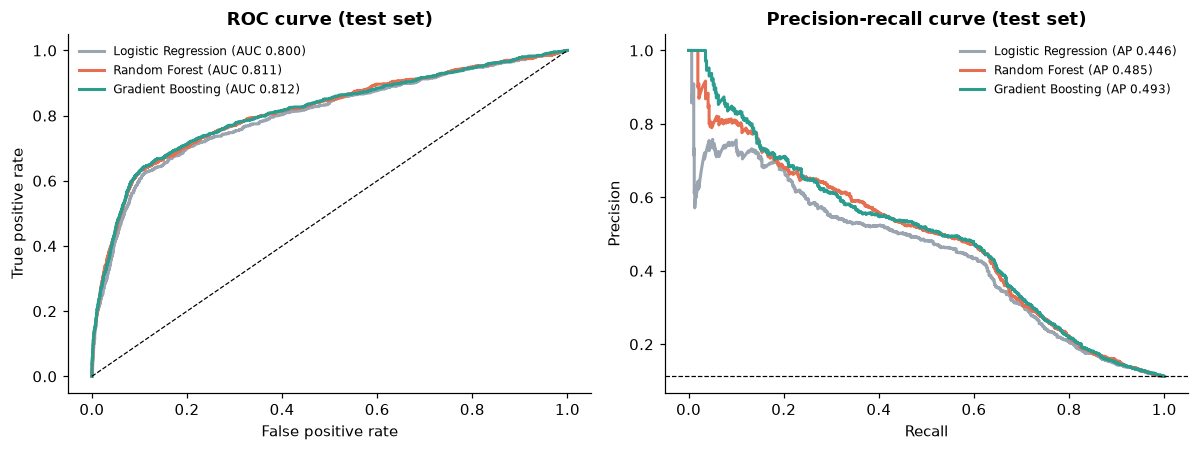

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2)); cols = {"Logistic Regression": GREY, "Random Forest": ORANGE, "Gradient Boosting": TEAL}
for n, p in probs.items():
    f, t, _ = roc_curve(yte, p); axes[0].plot(f, t, color=cols[n], lw=2, label=f"{n} (AUC {roc_auc_score(yte, p):.3f})")
    pr, rc, _ = precision_recall_curve(yte, p); axes[1].plot(rc, pr, color=cols[n], lw=2, label=f"{n} (AP {average_precision_score(yte, p):.3f})")
axes[0].plot([0, 1], [0, 1], ls="--", color="k", lw=.8); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curve (test set)")
axes[1].axhline(BASE, ls="--", color="k", lw=.8); axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curve (test set)")
for a in axes: a.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "05_roc_pr_curves.png"); plt.show()

### Leakage check — what happens if we include `duration`?
Shown purely as a warning: the number looks great, but it cannot be used to choose whom to call.

In [5]:
Xd = df[FEATURES + ["duration"]]; Xdtr, Xdte, _, _ = train_test_split(Xd, y, test_size=.2, stratify=y, random_state=42)
pre_d = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT), ("num", "passthrough", NUM + ["duration"])], sparse_threshold=0)
gb_d = Pipeline([("pre", pre_d), ("m", HistGradientBoostingClassifier(learning_rate=.05, max_iter=250, max_leaf_nodes=15, l2_regularization=1.0, random_state=42))]).fit(Xdtr, ytr)
auc_d = roc_auc_score(yte, gb_d.predict_proba(Xdte)[:, 1]); auc_c = cmp_.set_index("model").loc["Gradient Boosting", "test_roc_auc"]
leak = pd.DataFrame({"model": ["Gradient Boosting - usable (no duration)", "Gradient Boosting - WITH duration (leakage)"], "test_roc_auc": [auc_c, auc_d]}).round(4)
leak.to_csv(TAB / "05_leakage_check.csv", index=False); leak

,model,test_roc_auc
0,Gradient Boosting - usable (no duration),0.8121
1,Gradient Boosting - WITH duration (leakage),0.9513


### Robustness checks
1. **Without macro-economic indicators** — are we just learning *when* calls were made (the economy moved a lot over 2008-2010)?
2. **Chronological split** — train on the earliest 80% of calls and test on the latest 20% (rows are in time order), closer to real deployment than a random split.

In [6]:
MACRO = ["emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"]
def gb(cat, num):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), cat), ("num", "passthrough", num)], sparse_threshold=0)
    return Pipeline([("pre", pre), ("m", HistGradientBoostingClassifier(learning_rate=.05, max_iter=250, max_leaf_nodes=15, l2_regularization=1.0, random_state=42))])
num_nm = [c for c in NUM if c not in MACRO]
m1 = gb(CAT, num_nm).fit(Xtr[CAT + num_nm], ytr); a1 = roc_auc_score(yte, m1.predict_proba(Xte[CAT + num_nm])[:, 1])
cut = int(len(df) * .8); tr, te = df.iloc[:cut], df.iloc[cut:]
m2 = gb(CAT, NUM).fit(tr[FEATURES], tr.subscribed); a2 = roc_auc_score(te.subscribed, m2.predict_proba(te[FEATURES])[:, 1])
m3 = gb(CAT, num_nm).fit(tr[CAT + num_nm], tr.subscribed); a3 = roc_auc_score(te.subscribed, m3.predict_proba(te[CAT + num_nm])[:, 1])
rob = pd.DataFrame({"check": ["Random split, all features (selected model)", "Random split, NO macro features", "Chronological split, all features", "Chronological split, NO macro features"],
                    "test_roc_auc": [auc_c, a1, a2, a3]}).round(4)
rob.to_csv(TAB / "05_robustness_checks.csv", index=False); rob

,check,test_roc_auc
0,"Random split, all features (selected model)",0.8121
1,"Random split, NO macro features",0.7810
2,"Chronological split, all features",0.6377
3,"Chronological split, NO macro features",0.6671


## 3. Selected model: lift and cumulative gains

In [7]:
best = cmp_.sort_values("test_roc_auc", ascending=False).iloc[0].model; print("Selected model:", best)
p = probs[best]
g = pd.DataFrame({"p": p, "y": yte.values}).sort_values("p", ascending=False).reset_index(drop=True)
g["decile"] = pd.qcut(g.index, 10, labels=range(1, 11))
dec = g.groupby("decile", observed=True).agg(customers=("y", "size"), subscribers=("y", "sum"), avg_score=("p", "mean"))
dec["conversion_rate"] = dec.subscribers / dec.customers; dec["lift"] = dec.conversion_rate / g.y.mean()
dec["cum_customers_pct"] = dec.customers.cumsum() / dec.customers.sum(); dec["cum_capture_pct"] = dec.subscribers.cumsum() / dec.subscribers.sum()
dec.round(4).to_csv(TAB / "05_decile_lift_table.csv"); dec.round(3)

Selected model: Gradient Boosting


,customers,subscribers,avg_score,conversion_rate,lift,cum_customers_pct,cum_capture_pct
decile,,,,,,,
1,824,437,0.498,0.530,4.707,0.1,0.471
2,824,183,0.200,0.222,1.971,0.2,0.668
3,823,68,0.087,0.083,0.733,0.3,0.741
4,824,51,0.069,0.062,0.549,0.4,0.796
5,823,37,0.060,0.045,0.399,0.5,0.836
6,824,32,0.054,0.039,0.345,0.6,0.871
7,823,32,0.046,0.039,0.345,0.7,0.905
8,824,35,0.040,0.042,0.377,0.8,0.943
9,823,28,0.034,0.034,0.302,0.9,0.973


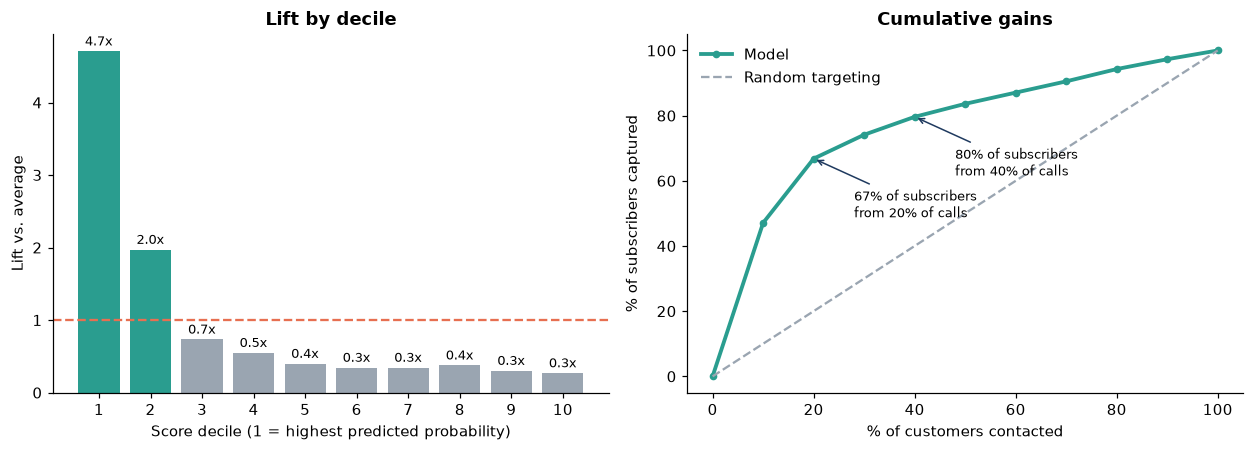

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))
axes[0].bar(dec.index.astype(str), dec.lift, color=[TEAL if l > 1 else GREY for l in dec.lift]); axes[0].axhline(1, ls="--", color=ORANGE)
for i, v in enumerate(dec.lift): axes[0].text(i, v + .08, f"{v:.1f}x", ha="center", fontsize=8.5)
axes[0].set_xlabel("Score decile (1 = highest predicted probability)"); axes[0].set_ylabel("Lift vs. average"); axes[0].set_title("Lift by decile")
xs = np.r_[0, dec.cum_customers_pct * 100]; ys = np.r_[0, dec.cum_capture_pct * 100]
axes[1].plot(xs, ys, color=TEAL, lw=2.5, marker="o", ms=4, label="Model"); axes[1].plot([0, 100], [0, 100], ls="--", color=GREY, label="Random targeting")
for k in (2, 4):
    axes[1].annotate(f"{ys[k]:.0f}% of subscribers\nfrom {xs[k]:.0f}% of calls", (xs[k], ys[k]), (xs[k] + 8, ys[k] - 18), arrowprops=dict(arrowstyle="->", color=NAVY), fontsize=8.5)
axes[1].set_xlabel("% of customers contacted"); axes[1].set_ylabel("% of subscribers captured"); axes[1].set_title("Cumulative gains"); axes[1].legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / "05_lift_and_gains.png"); plt.show()

## 4. What drives the model? (permutation importance on the test set)

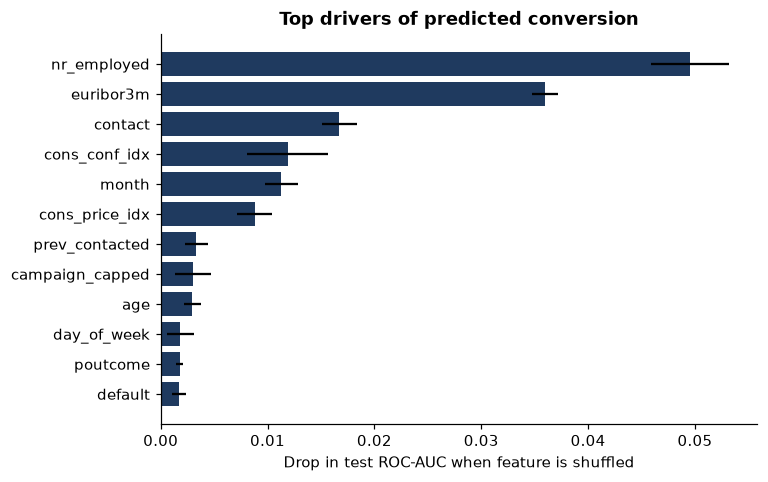

,feature,auc_drop,std
18,nr_employed,0.0495,0.0037
17,euribor3m,0.0360,0.0012
6,contact,0.0167,0.0016
16,cons_conf_idx,0.0119,0.0038
7,month,0.0113,0.0015
15,cons_price_idx,0.0088,0.0016
13,prev_contacted,0.0033,0.0011
11,campaign_capped,0.0031,0.0017
10,age,0.0030,0.0008
8,day_of_week,0.0018,0.0013


In [9]:
pi = permutation_importance(models[best], Xte, yte, scoring="roc_auc", n_repeats=5, random_state=42, n_jobs=1)
imp = pd.DataFrame({"feature": FEATURES, "auc_drop": pi.importances_mean, "std": pi.importances_std}).sort_values("auc_drop", ascending=False)
imp.round(4).to_csv(TAB / "05_feature_importance.csv", index=False)
top = imp.head(12)[::-1]
fig, ax = plt.subplots(figsize=(7, 4.6)); ax.barh(top.feature, top.auc_drop, xerr=top["std"], color=NAVY)
ax.set_xlabel("Drop in test ROC-AUC when feature is shuffled"); ax.set_title("Top drivers of predicted conversion")
fig.savefig(FIG / "05_feature_importance.png"); plt.show(); imp.head(12).round(4)

## 5. Business impact: how many calls should we make?
**Illustrative assumptions** (replace with the bank's actual figures): each call attempt costs **€10**; a subscribed deposit is worth **€100** in net margin. Break-even conversion rate = 10% — below that a call loses money.

In [10]:
COST, VALUE = 10, 100
n = len(g); cum_sub = g.y.cumsum().values; calls = np.arange(1, n + 1)
profit_model = cum_sub * VALUE - calls * COST
profit_random = calls * (g.y.mean() * VALUE - COST)
k_opt = int(profit_model.argmax()) + 1
scale = len(df) / n   # scale test-set results to the full 41k base
summary = pd.DataFrame({
  "strategy": ["Call everyone (baseline)", "Call top-scored customers only (model cut-off)"],
  "calls_pct": [100, k_opt / n * 100],
  "subscribers_captured_pct": [100, cum_sub[k_opt - 1] / g.y.sum() * 100],
  "profit_full_base_eur": [profit_random[-1] * scale, profit_model[k_opt - 1] * scale],
})
summary["calls_full_base"] = (summary.calls_pct / 100 * len(df)).round(0)
summary["profit_per_call_eur"] = summary.profit_full_base_eur / summary.calls_full_base
summary.round(2).to_csv(TAB / "05_profit_scenarios.csv", index=False)
print(f"Optimal cut-off: contact top {k_opt / n:.0%} of customers (score >= {g.p.iloc[k_opt - 1]:.3f})"); summary.round(1)

Optimal cut-off: contact top 19% of customers (score >= 0.115)


,strategy,calls_pct,subscribers_captured_pct,profit_full_base_eur,calls_full_base,profit_per_call_eur
0,Call everyone (baseline),100.0,100.0,52194.9,41176.0,1.3
1,Call top-scored customers only (model cut-off),19.3,66.5,229027.8,7944.0,28.8


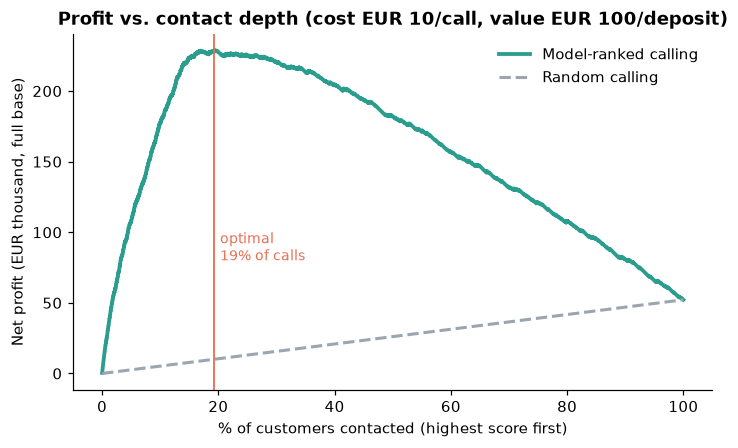

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4.2)); x = calls / n * 100
ax.plot(x, profit_model * scale / 1000, color=TEAL, lw=2.5, label="Model-ranked calling"); ax.plot(x, profit_random * scale / 1000, color=GREY, ls="--", lw=2, label="Random calling")
ax.axvline(k_opt / n * 100, color=ORANGE, lw=1.2); ax.text(k_opt / n * 100 + 1, profit_model.max() * scale / 1000 * .35, f"optimal\n{k_opt / n:.0%} of calls", color=ORANGE, fontsize=9)
ax.set_xlabel("% of customers contacted (highest score first)"); ax.set_ylabel("Net profit (EUR thousand, full base)")
ax.set_title(f"Profit vs. contact depth (cost EUR {COST}/call, value EUR {VALUE}/deposit)"); ax.legend(frameon=False)
fig.savefig(FIG / "05_profit_curve.png"); plt.show()

## 6. Score bands for the call centre

In [12]:
bands = pd.cut(g.p.rank(ascending=False, pct=True), [0, .1, .3, .6, 1.0], labels=["A (top 10%)", "B (next 20%)", "C (next 30%)", "D (bottom 40%)"])
bt = g.groupby(bands, observed=True).agg(customers=("y", "size"), conversion_rate=("y", "mean"), min_score=("p", "min"))
bt.index.name = "score_band"; bt["lift"] = bt.conversion_rate / g.y.mean(); bt["recommended_action"] = ["Call first, senior agents", "Call, standard script", "Call only if capacity allows", "Do not call / use low-cost channel"]
bt.round(3).to_csv(TAB / "05_score_bands.csv"); bt.round(3)

,customers,conversion_rate,min_score,lift,recommended_action
score_band,,,,,
A (top 10%),823,0.531,0.321,4.712,"Call first, senior agents"
B (next 20%),1647,0.152,0.074,1.353,"Call, standard script"
C (next 30%),2471,0.049,0.050,0.431,Call only if capacity allows
D (bottom 40%),3295,0.036,0.018,0.323,Do not call / use low-cost channel


## Key findings
* **Gradient Boosting** is selected: test **ROC-AUC 0.812**, PR-AUC 0.493 (vs 0.113 for random). Differences between the three models are small.
* **Targeting power:** the top 10% of scores convert at **53.1%** (4.7x lift); the top 20% captures **66.8%** of all subscribers and the top 40% captures **79.6%**.
* **Leakage is real:** adding `duration` pushes AUC to 0.951 — misleading for a pre-call model.
* **Drivers:** the economic indicators (`nr_employed`, `euribor3m`, `cons_conf_idx`) lead, followed by contact channel and month.
* **Profit illustration:** calling only the top-scored ~19% (~7,900 of 41k calls) captures 66% of subscribers and lifts profit per call from about EUR 1 to EUR 29 under the stated cost/value assumptions.

### Honest limitations
* **Out-of-time performance is much weaker.** When trained on earlier calls and tested on the latest 20%, AUC falls to **0.64 (all features) / 0.67 (no macro features)**. The 0.81 figure comes from a random split and is therefore optimistic for real deployment; the data covers one unusual period (2008-2010 financial crisis).
* Because macro variables dominate, the model partly learns *when* calls happened. Use it as a ranking aid, re-train regularly, and validate on a live holdout before relying on it.
* The profit cut-off is chosen on the test set and the EUR 10 / EUR 100 assumptions are illustrative.